#ATIVIDADE INTEGRADORA - SISTEMA DE COMUNICAÇÃO INTERPLANETÁRIA DA COLÔNIA (SCIC)

- passo a passo
- organizar dados
    - operacionais
    - comunicação
- avaliar a confiabilidade de previsões simples
- priorizar alertas criticos
- permitir consulta eficiente
- gerar um relatório tecnico de apoio a decisão

***Não será obrigatório integrar sensores físicos, APIs externas, hardware real, sistemas de supervisão e telemetria, sistemas avançados de gerenciamento de rede, dashboards web ou redes neurais profundas. Esses recursos podem ser simulados, desde que estejam relacionados aos conteúdos trabalhados nas disciplinas***

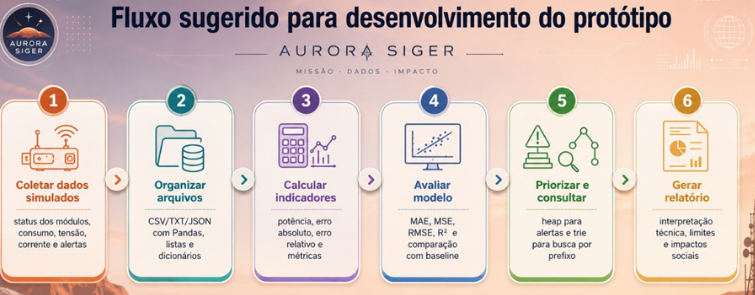

*Trabalho realizado por Caio Aguiar Leonardo RM:572349*

#Base de dados
***
* Nome do módulo;

* Tipo do módulo, como habitação,
agricultura, comunicação, laboratório, suporte médico ou armazenamento de dados;

* Latência observada;

* Latência prevista ou estimada;

* Tensão, corrente, potência aproximada ou potência de transmissão;

* Status operacional, como ativo, manutenção ou alerta;

* Nível de prioridade;

* Código do dispositivo ou sensor;

* Mensagem resumida do alerta;
Data ou ciclo de registro.***

        dataset = {["nome_modulo": "Hab 3.0, HP 2.0, Comas 3.0, DATAS 1.0"
                    "Tipo": "Habitação, Mantimentos, Comunicação, Armazenamento de dados"
                    "latencia_Observada:" "",
                    "latencia_prev": "",
                    "corrente": "x kA",
                    "status": "Ativo, Manutenção, Alerta",
                    "prioridade": "3, 3, 2, 1",
                    "cod_sensor": "HAB-AS-201, HP-AS-202, CAS-AS-203, DT-AS-204",
                    "sms_alerta": "resumo do alerta",
                    "Data": "Data do registro"
                    ]
                ,
                }

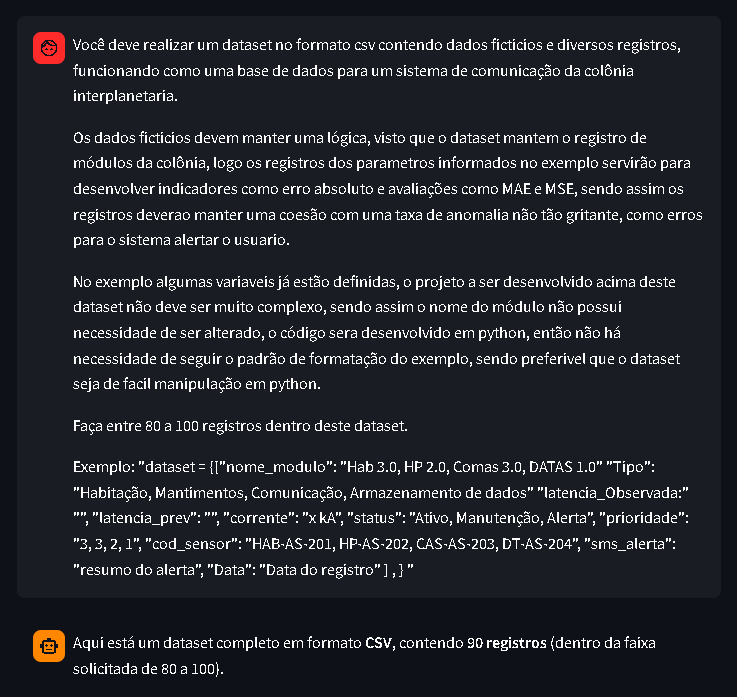

Este foi o processo realizado para obtenção do dados_comunicacao.csv, dataset gerado com dados ficticios, realizei tambem um tratamento acima desses dados para melhor leitura e manipulação, formatando letras maiusculas e parâmetros.

#Bibliotecas auxiliares

Para realização do código foram necessárias a instalação e importação das seguintes bibliotecas auxiliares.

Algumas bibliotecas foram adicionadas a fim de melhor interação com o usuário e vizualização dos dados:

In [1]:
!pip install pandas matplotlib numpy scikit-learn ipython jinja2

import csv
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import heapq
from datetime import datetime, timedelta
import time
import random
from IPython.display import  display, HTML

#Coleta de dados
***Status dos módulos, consumo, tensão, corrente e alertas***

Nesta etapa, realizei o armazenamento do dataset na váriavel dados para manipulação dos dados.

In [2]:
import pandas as pd

dados = pd.read_csv("colonia_comunicacao.csv")

display(dados)
display(dados.info())

,id_registro,data,hora,nome_modulo,tipo,cod_sensor,prioridade,latencia_prev,latencia_observada,corrente_ka,status,sms_alerta
0,1,2036-08-19,00:00:00,Hab 3.0,Habitação,HAB-AS-201,3,0.0,15.9,3.8,Alerta,Ruptura térmica em cabo de conexão exposto.
1,2,2036-08-19,00:00:00,HP 2.0,Mantimentos,HP-AS-202,3,20.1,19.9,1.8,Ativo,Operação normal
2,3,2036-08-19,00:00:00,Comas 3.0,Comunicação,CAS-AS-203,2,12.5,NaN,NaN,Manutenção,Manutenção programada
3,4,2036-08-19,00:00:00,DATAS 1.0,Armazenamento de dados,DT-AS-204,1,8.0,9.0,1.5,Ativo,Operação normal
4,5,2036-08-19,04:00:00,Hab 3.0,Habitação,HAB-AS-201,3,0.0,17.6,5.7,Alerta,Queda de conectividade na antena parabólica pr...
...,...,...,...,...,...,...,...,...,...,...,...,...
75,76,2036-08-22,00:00:00,DATAS 1.0,Armazenamento de dados,DT-AS-204,1,8.0,8.5,1.5,Ativo,Operação normal
76,77,2036-08-22,04:00:00,Hab 3.0,Habitação,HAB-AS-201,3,15.2,17.5,2.4,Ativo,Operação normal
77,78,2036-08-22,04:00:00,HP 2.0,Mantimentos,HP-AS-202,3,20.0,19.9,1.8,Ativo,Operação normal
78,79,2036-08-22,04:00:00,Comas 3.0,Comunicação,CAS-AS-203,2,12.4,14.7,3.1,Ativo,Operação normal


<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_registro         80 non-null     int64  
 1   data                80 non-null     str    
 2   hora                80 non-null     str    
 3   nome_modulo         80 non-null     str    
 4   tipo                80 non-null     str    
 5   cod_sensor          80 non-null     str    
 6   prioridade          80 non-null     int64  
 7   latencia_prev       80 non-null     float64
 8   latencia_observada  75 non-null     float64
 9   corrente_ka         75 non-null     float64
 10  status              80 non-null     str    
 11  sms_alerta          80 non-null     str    
dtypes: float64(3), int64(2), str(7)
memory usage: 14.0 KB


None

#Organização dos dados
***CSV/TXT/JSON com pandas, listas e dicionários***

Agora, realizei a criação de listas auxiliares no formato txt e json, ambas as listas contendo parâmetros diferentes, a escolha de onde cada parâmetro do dataset se encaixaria um foi decidida a partir da manipulação necessária dos dados.

No arquivo TXT foram salvos os parâmetros de latencia prevista, latencia observada e corrente, já no Json os demais dados, estas listas foram desenvolvidas com intuito de facilitar a manipulação dos dados ao longo do código.

In [3]:
##Criando arquivo auxiliar json
#Criando o dicionário com Nome, Tipo, Sensor e Prioridade
dic_nome = dict(zip(dados["nome_modulo"], zip(dados["tipo"], dados["cod_sensor"], dados["prioridade"])))

#Filtrando os alertas - Usamos orient='records' para gerar uma lista de dicionários com itens definidos
dic_alerta = dados[dados['status']=='Alerta'].to_dict(orient='records')

#Removendo datas duplicadas antes de converter para dicionário
datas_unicas = dados["data"].drop_duplicates().reset_index(drop=True).to_dict()
horas_unicas = dados["hora"].drop_duplicates().reset_index(drop=True).to_dict()
dic_data = {
    "datas": datas_unicas,
    "horas": horas_unicas
}

#Agrupando tudo em um único dicionário
dados_completos = {
    "modulos": dic_nome,
    "alertas": dic_alerta,
    "datas": dic_data
}

#Salvando no arquivo como um único objeto JSON válido
with open("dados_json.json", "w", encoding="utf-8") as arquivo_json:
    json.dump(dados_completos, arquivo_json, indent=4, ensure_ascii=False)
print("........Arquivo Json: OK.........")


........Arquivo Json: OK.........


In [4]:
##Criando arquivo auxiliar TXT
ids = []
latenciaobv = []
latenciaprev = []
corrente = []

#Lendo os dados do arquivo CSV
with open("colonia_comunicacao.csv", mode='r') as arquivo_csv:
    # O delimitador do CSV é a vírgula
    leitor = csv.DictReader(arquivo_csv, delimiter=',')
    for linha in leitor:
        # Extraímos os valores sem espaços em branco
        val_prev = linha['latencia_prev'].strip()
        val_obv = linha['latencia_observada'].strip()
        val_corrente = linha['corrente_ka'].strip()
        # Verificamos a existência de campos vazios nas colunas
        if val_prev == '' or val_obv == '' or val_corrente == '':
            continue
        val_previ = float(val_prev)
        val_obvi = float(val_obv)
        val_correntei = float(val_corrente)
        if val_previ == 0.0:
            continue
        # Extraímos os dados, convertendo para float ou int
        ids.append(int(linha['id_registro']))
        latenciaprev.append(float(val_prev))
        latenciaobv.append(float(val_obv))
        corrente.append(float(val_corrente))


#Salvando as 3 variáveis no novo arquivo .txt
with open('dados_txt.txt', mode='w') as arquivo_txt:
    arquivo_txt.write("ID;latencia_prev;latencia_obv;corrente\n")
    for id_reg, lp, lo, corr in zip(ids, latenciaprev, latenciaobv, corrente):
        arquivo_txt.write(f"{id_reg};{lp};{lo};{corr}\n")

print("........Arquivo TXT:  OK.........")

........Arquivo TXT:  OK.........


#Indicadores
***Potência, erro absoluto, erro relativo e métricas***

***Aplicar, no mínimo, erro absoluto e erro relativo***

* Erro absoluto entre latência prevista e latência observada;
* Erro relativo para comparar módulos com escalas diferentes de latência;
* Interpretação de possíveis diferenças numéricas causadas por aproximações, arredondamentos ou representação em ponto flutuante;
* Discussão sobre quando um erro pode ser considerado aceitável ou preocupante no contexto da colônia.

* evolução de uma variável ao longo do tempo, coma latência, estabilidade do enlace ou qualidade do sinal de um módulo. Essa simulação deve permanecer no nível estudado na disciplina, sem exigir modelos físicos avançados.

Este foram os código desenvolvidos para armazenar os dados solicitados e realizar o erro absoluto e erro relativo, e tambêm quais os gráficos utilizados para análise desses indicadores.

Cada gráfico desenvolvido foi pensado para ser executado livremente, possuindo a análise do gráfico integrada ao plot, o código foi pensado para ser executado em looping e podendo ser executado em um editor de código, assim o usuário pode realizar o download do gráfico com a análise.

*Neste arquivo, a exibição em looping, possuindo a opção do escolha do gráfico a ser exibido foi desativada para melhor vizualização.*


Gráfico de dispersão gerado com a análise integrada.


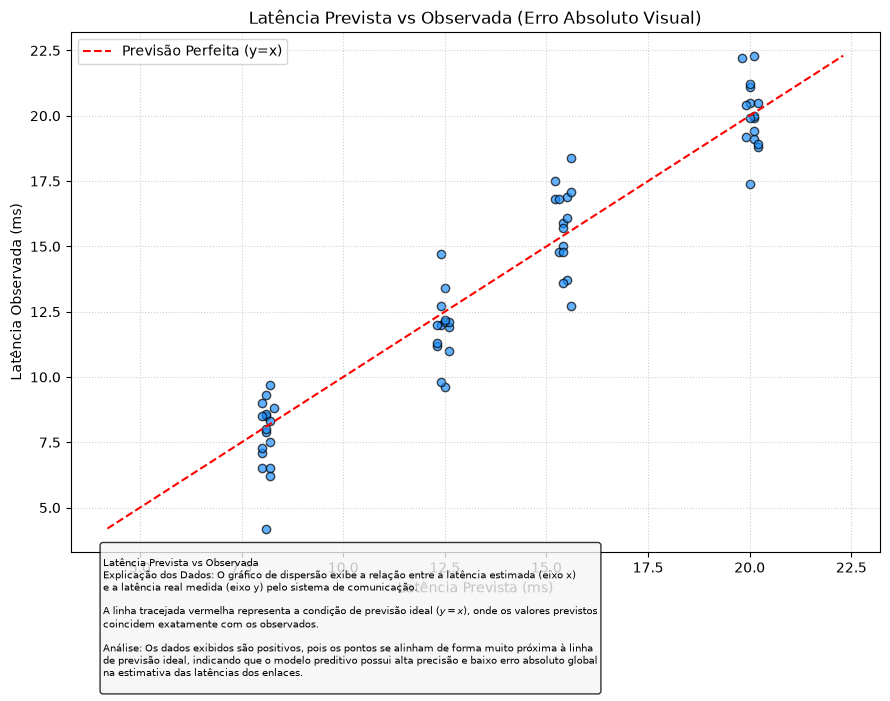


Gráfico de caixa gerado com a análise integrada.


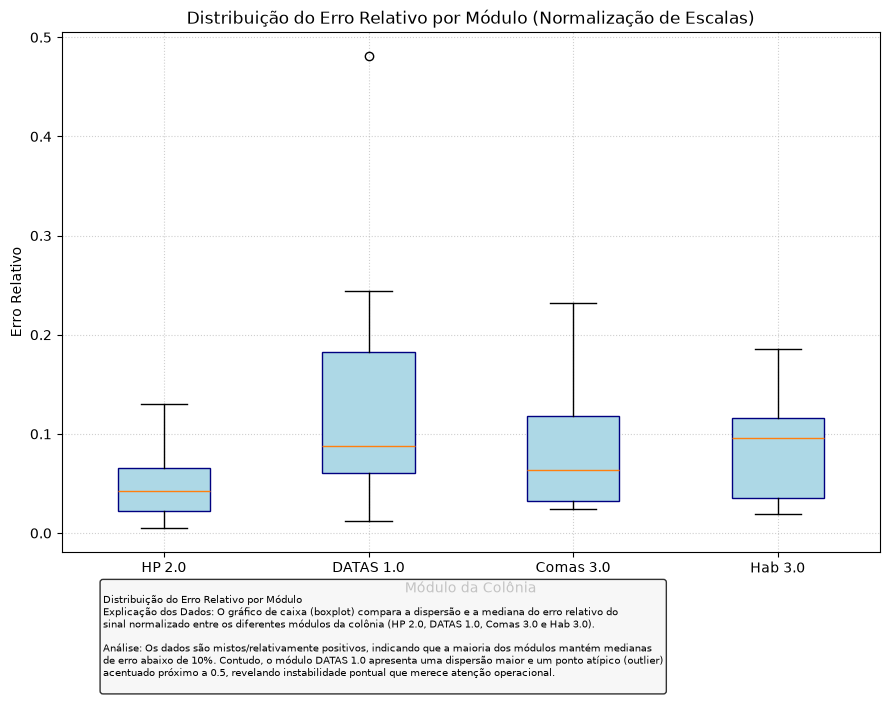


Evolução temporal gerada com a análise integrada.


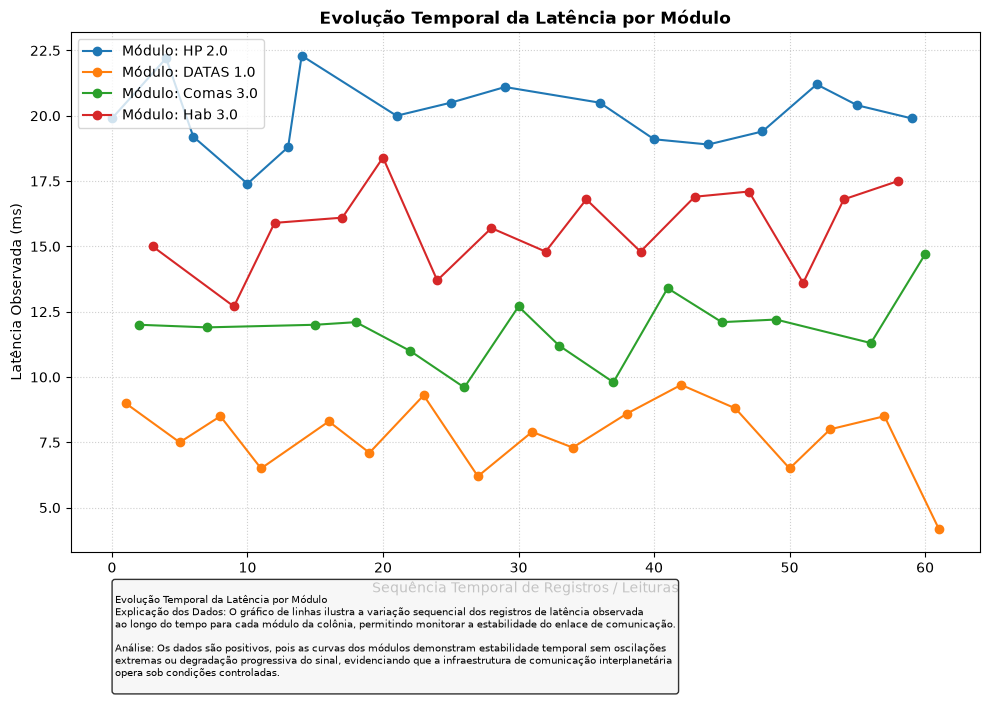

In [6]:
#Erro absoluto entre latência prevista e latência observada
#Bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#Criação de variavel auxiliar para retirar 0 ou NaN
dadosva = dados.dropna(subset=['latencia_prev', 'latencia_observada']).copy()
dadosva = dadosva[dadosva['latencia_prev'] != 0.0]
dadosva = dadosva.reset_index(drop=True)

dadosva['erro_absoluto'] = abs(dadosva['latencia_prev'] - dadosva['latencia_observada'])

dadosva['erro_relativo'] = dadosva['erro_absoluto'] / dadosva['latencia_prev']

dadosva['erro_absoluto'] = dadosva['erro_absoluto'].round(4)
dadosva['erro_relativo'] = dadosva['erro_relativo'].round(4)

latpre1 = """
Latência Prevista vs Observada
Explicação dos Dados: O gráfico de dispersão exibe a relação entre a latência estimada (eixo x)
e a latência real medida (eixo y) pelo sistema de comunicação.

A linha tracejada vermelha representa a condição de previsão ideal ($y=x$), onde os valores previstos
coincidem exatamente com os observados.

Análise: Os dados exibidos são positivos, pois os pontos se alinham de forma muito próxima à linha
de previsão ideal, indicando que o modelo preditivo possui alta precisão e baixo erro absoluto global
na estimativa das latências dos enlaces.
"""

latpre2 = """
Distribuição do Erro Relativo por Módulo
Explicação dos Dados: O gráfico de caixa (boxplot) compara a dispersão e a mediana do erro relativo do
sinal normalizado entre os diferentes módulos da colônia (HP 2.0, DATAS 1.0, Comas 3.0 e Hab 3.0).

Análise: Os dados são mistos/relativamente positivos, indicando que a maioria dos módulos mantém medianas
de erro abaixo de 10%. Contudo, o módulo DATAS 1.0 apresenta uma dispersão maior e um ponto atípico (outlier)
acentuado próximo a 0.5, revelando instabilidade pontual que merece atenção operacional.
"""

latpre3 = """
Evolução Temporal da Latência por Módulo
Explicação dos Dados: O gráfico de linhas ilustra a variação sequencial dos registros de latência observada
ao longo do tempo para cada módulo da colônia, permitindo monitorar a estabilidade do enlace de comunicação.

Análise: Os dados são positivos, pois as curvas dos módulos demonstram estabilidade temporal sem oscilações
extremas ou degradação progressiva do sinal, evidenciando que a infraestrutura de comunicação interplanetária
opera sob condições controladas.
"""

#resp = input("Selecione a opção desejada: ")

#if resp == "1":
print("\nGráfico de dispersão gerado com a análise integrada.")
plt.figure(figsize=(9, 7))

plt.scatter(dadosva['latencia_prev'], dadosva['latencia_observada'], color='dodgerblue', alpha=0.7, edgecolors='k')
lims = [min(dadosva['latencia_prev'].min(), dadosva['latencia_observada'].min()),
    max(dadosva['latencia_prev'].max(), dadosva['latencia_observada'].max())]
plt.plot(lims, lims, color='red', linestyle='--', label='Previsão Perfeita (y=x)')
plt.title('Latência Prevista vs Observada (Erro Absoluto Visual)')
plt.xlabel('Latência Prevista (ms)')
plt.ylabel('Latência Observada (ms)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


texto_analise = (latpre1)
plt.figtext(0.12, 0.01, texto_analise, fontsize=7, bbox=dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8))

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

#elif resp == "2":
print("\nGráfico de caixa gerado com a análise integrada.")
plt.figure(figsize=(9, 7))

modulos_unicos = dadosva['nome_modulo'].unique()
dados_boxplot = [dadosva[dadosva['nome_modulo'] == m]['erro_relativo'] for m in modulos_unicos]
plt.boxplot(dados_boxplot, tick_labels=modulos_unicos, patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='navy'))
plt.title('Distribuição do Erro Relativo por Módulo (Normalização de Escalas)')
plt.xlabel('Módulo da Colônia')
plt.ylabel('Erro Relativo')
plt.grid(True, linestyle=':', alpha=0.6)

texto_analise = (latpre2)
plt.figtext(0.12, 0.01, texto_analise, fontsize=7, bbox=dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8))

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

#elif resp == "3":
print("\nEvolução temporal gerada com a análise integrada.")
plt.figure(figsize=(10, 7))

for modulo in dadosva['nome_modulo'].unique():
    subset = dadosva[dadosva['nome_modulo'] == modulo]
    plt.plot(subset.index, subset['latencia_observada'], marker='o', linestyle='-', label=f'Módulo: {modulo}')

plt.title("Evolução Temporal da Latência por Módulo", fontsize=12, fontweight='bold')
plt.xlabel("Sequência Temporal de Registros / Leituras", fontsize=10)
plt.ylabel("Latência Observada (ms)", fontsize=10)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)

texto_analise = (latpre3)
plt.figtext(0.12, 0.01, texto_analise, fontsize=7, bbox=dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8))

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

#Avaliação
***MAE, MSE, RMSE, R² e comparação com baseline***

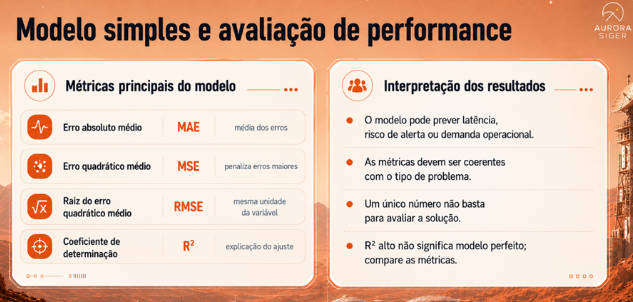

Para a avaliação da performance, as variaveis de MAE, MSE, RMSE e R² foram calculadas e avaliadas, o texto de interpretação das variáveis foi realizado para que se pareça uma análise de inteligencia artificial que estaria "avaliando em tempo real" os dados.

In [7]:
import numpy as np

#Erro médio absoluto (MAE)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(latenciaobv, latenciaprev)
print(f"MAE  : ms {mae:,.2f}")

#Erro médio quadratico (MSE)
mse = mean_squared_error(latenciaobv, latenciaprev)
print(f"MSE  : {mse:,.2f}")
#Coeficiente de determinação (R²)
r2 = r2_score(latenciaobv, latenciaprev)
print(f"R²   : {r2:.4f}")
#Raiz do erro quadrático médio (RMSE)
rmse = np.sqrt(mse)
print(f"RMSE : ms {rmse:,.2f}")

##INTERPRETAR RESULTADOS:
avalia = f"""Avaliações do SCIC:\n
MAE  :\n
Mede a magnitude média dos erros absolutos entre as previsões e os valores reais,\n
na mesma unidade de medida (milissegundos).\n
Valores mais próximos de zero indicam previsões mais precisas.\n
Resultado: Um erro médio de apenas 1,12 ms mostra que, em média, as previsões do sistema \n
erram por uma margem muito pequena.\n

MSE  : \n
Por elevar os erros ao quadrado, ele penaliza de forma mais severa desvios maiores.\n
Valores menores indicam melhor desempenho.\n
Resultado: Favorável, pois um valor de 2,00 indica que o nível geral de erros ao quadrado é baixo.\n

R²   : \n
Representa a proporção da variância dos dados que é explicada pelo modelo. \n
Varia geralmente de 0 a 1, sendo que valores mais próximos de 1 indicam um ajuste excelente.\n
Resultado: Favorável. Um resultado de 0,9155 significa que cerca de 91,55% da \n
variabilidade dos dados é explicada pelo sistema.\n

RMSE : \n
É a raiz quadrada do MSE, retornando à unidade original dos dados.\n
Mostra o desvio padrão dos resíduos do modelo.\n
Resultado: Favorável. O valor de 1,41 ms reforça que o erro típico do sistema está\n
em um patamar bastante reduzido e controlado."""

MAE  : ms 1.12
MSE  : 2.00
R²   : 0.9155
RMSE : ms 1.41


#Consulta e prioridade
***Heap para alertas e trie para busca de prefixo***

                    HEAP
  * ALERTAS EM PRIORIDADE
  * Criticidade nos indicadores
  * Latência elevada
  * Módulo essencial
  * Tempo do ultimo registro

  A equipe deverá demonstrar:

* Como os alertas foram representados;
* Qual critério foi utilizado para definir prioridade;
* Como a estrutura heap organiza os alertas;
* Como o sistema seleciona o alerta mais urgente;
* Qual é a vantagem dessa estrutura em relação a uma lista simples.

                  TRIE

***O sistema deverá possuir uma funcionalidade de busca por prefixo utilizando o conceito de trie. Essa busca poderá ser aplicada a nomes de módulos, códigos de sensores, palavras-chave de alertas ou comandos cadastrados.***

Opção de busca -> Busque no SCIC -> Ao digitar “com”, o sistema retorna “Comunicação”, “Controle” e confirma se esta correto -> Se sim mostra os indicadores do módulo


Uma funcionalidade adicionada ao código para demonstrar realidade e fideldade é a inclusão de uma prioridade caso o status da ultima linha adicionada ao dataset pelo sistema estiver em "alerta", visto que esta condição é a mais recente possivel, o sistema deve considerar que este é o alerta com a maior importancia a ser resolvido.

A seguir estão os códigos desenvolvidos respectivamente para o sistema de HEAP e TRIE:

In [8]:
###ALERTAS HEAP
# Classe para gerenciar a fila de prioridade (Heap)
print(".....Gerando fila de alertas.....")
time.sleep(0.5)
class FilaDeAlertas:
    def __init__(self):
        self.heap = []
        self.ultimo_timestamp_geral = 0.0

    def extrair_timestamp(self, registro):
        try:
            data_str = str(registro.get('data', '1970-01-01')).strip()
            hora_str = str(registro.get('hora', '00:00:00')).strip()
            formato = "Format: %Y-%m-%d %H:%M:%S"
            formato = "%-d/%m/%Y %H:%M:%S" if '/' in data_str else "%Y-%m-%d %H:%M:%S"
            dt = datetime.strptime(f"{data_str} {hora_str}", formato)
            return dt.timestamp()
        except:
            return 0.0

    def calcular_score(self, registro):
        score = 0
        status_registro = str(registro.get('status', '')).strip().lower()
        timestamp_atual = self.extrair_timestamp(registro)
        # Peso 1: Status em alerta
        if str(registro.get('status')).strip().lower() == 'alerta':
            score += 10000
            if timestamp_atual == self.ultimo_timestamp_geral:
                score += 100000
        # Peso 2: Prioridade
        try:
            prioridade = int(registro.get('prioridade', 1))
            if prioridade == 3:
                score += 3000
            elif prioridade == 2:
                score += 1500
            elif prioridade == 1:
                score += 200
        except (ValueError, TypeError):
            pass
        # Peso 3: O quão distante a latência observada ficou da prevista
        try:
            erro_rel = float(registro.get('erro_relativo', 0))
            if erro_rel > 0:
                score += (erro_rel * 500) # Peso sobre a porcentagem de erro
        except:
            pass
        # Peso 4: Latência elevada
        try:
            latencia = float(registro.get('latencia_observada', 0))
            if latencia > 15:
                score += latencia * 5
        except:
            pass
        return score

    def adicionar_registro(self, registro):
        score = self.calcular_score(registro)
        timestamp = self.extrair_timestamp(registro)
        # -score: Para que o heapq (que é min-heap) tire o MAIOR score primeiro.
        # timestamp: Critério de desempate (menor timestamp = registro mais antigo sai primeiro).
        # id_registro: Evita erros de comparação entre dicionários se score e tempo forem idênticos.
        id_reg = registro.get('id_registro', 0)
        heapq.heappush(self.heap, (-score, timestamp, id_reg, registro))

    def processar_proximo_alerta(self):
        if self.heap:
            score_negativo, timestamp, id_reg, registro = heapq.heappop(self.heap)
            score_real = -score_negativo
            return score_real, registro
        return None, None

# 3. Populando o Heap com os dados (dadosva)
fila_alertas = FilaDeAlertas()

# Convertendo o dataframe para lista de dicionários e adicionando à fila
registros_dict = dadosva.to_dict(orient='records')
timestamps_todos = [fila_alertas.extrair_timestamp(reg) for reg in registros_dict]
if timestamps_todos:
    fila_alertas.ultimo_timestamp_geral = max(timestamps_todos)
for reg in registros_dict:
    fila_alertas.adicionar_registro(reg)


.....Gerando fila de alertas.....


In [9]:
###SISTEMA DE BUSCA COM TRIE
print("...A inicializar o sistema de busca com Trie...")
time.sleep(0.5)

class NoTrie:
    def __init__(self):
        self.filhos = {}
        self.e_fim = False
        self.indices_linhas = set()

class TrieBusca:
    def __init__(self):
        self.raiz = NoTrie()

    def inserir(self, termo, indice_linha):
        #Ignora valores nulos/vazios típicos de CSVs
        if pd.isna(termo):
            return

        no = self.raiz
        termo_normalizado = str(termo).strip().lower()

        #Armazena o índice da linha em todos os nós do caminho do prefixo
        for char in termo_normalizado:
            if char not in no.filhos:
                no.filhos[char] = NoTrie()
            no = no.filhos[char]
            if indice_linha is not None:
                no.indices_linhas.add(indice_linha)
        no.e_fim = True

    def buscar_por_prefixo(self, prefixo):
        """Retorna uma lista com as opções encontradas e os índices correspondentes."""
        no = self.raiz
        prefixo_normalizado = str(prefixo).strip().lower()

        for char in prefixo_normalizado:
            if char not in no.filhos:
                return set(), []
            no = no.filhos[char]

        #Coleta os termos completos a partir do nó onde parou
        opcoes_encontradas = set()
        self._coletar_termos(no, prefixo_normalizado, opcoes_encontradas)
        return no.indices_linhas, list(opcoes_encontradas)

    def _coletar_termos(self, no, prefixo_atual, resultados):
        if no.e_fim:
            resultados.add(prefixo_atual)
        for char, no_filho in no.filhos.items():
            self._coletar_termos(no_filho, prefixo_atual + char, resultados)

#Integração com a base de dados
def indexar_base_de_dados(caminho_csv):
    print(f"A carregar o ficheiro '{caminho_csv}'...")
    df = pd.read_csv(caminho_csv)
    pd.set_option('display.max_colwidth', None)
    trie = TrieBusca()

    print("A indexar os dados (isto pode demorar alguns segundos)...")

    # 1. Indexar os nomes das colunas
    for coluna in df.columns:
        trie.inserir(coluna, None)

    # 2. Indexar as linhas e células
    for indice_linha, linha in df.iterrows():
        for coluna in df.columns:
            valor = linha[coluna]

            #Insere o valor completo da célula
            trie.inserir(valor, indice_linha)

            #Insere palavras individuais (para permitir encontrar partes de um texto)
            if isinstance(valor, str):
                palavras = valor.split()
                if len(palavras) > 1:
                    for palavra in palavras:
                        trie.inserir(palavra, indice_linha)

    print("Indexação concluída com sucesso!")
    return df, trie


...A inicializar o sistema de busca com Trie...


#Interação com o Usuário

Para iniciar esta etapa, criei algumas variaveis auxiliares para o funcionamento do loop e a segui defini os procedimentos necessários para exibição, chamada e interação com os processos até aqui desenvolvidos.

Alguns procedimentos criados servem exclusivamente para o funcionamento do loop e confirmação da interação:

In [10]:
###ITERAÇÃO COM O USUÁRIO
os.system("cls")
dialogo = 0
times_add = 0
ot0 = "0"
on0 = "0 - ALERTAS"
ot1 = "1"
on1 = "1 - Vizualizar base de dados"
ot2 = "2"
on2 = "2 - Métricas e avaliação do SCIC"
ot3 = "3"
on3 = "3 - Sistema de busca"
ot4 = "4"
on4 = "4 - Adicionar índice aos dados da colônia"
ot5 = "5"
on5 = "5 - Sair"

def voltar():
    print("Retornando a página inicial...\n")
    time.sleep(0.5)
    os.system("cls")

def confirmacao(nome):
    print("" + "=" * 45)
    print(f"\nVocê selecionou a opção Nº{nome}\n\n\n")
    resposta = input("Deseja continuar? (S/N)  ")
    if resposta == "N" or resposta == 'n':
        return 1
    elif resposta == "S" or resposta == "s":
        return 2

def saida():
    print("" + "=" * 45 + "\n")
    time.sleep(1.5)
    resp = input("Digite S para retornar:  ")
    if resp == "S" or resp == "s":
        voltar()
    else:
        print("Opção inválida, digite S para retornar à página inicial.\n")
        saida()


Agora realizei a definição de procedimentos como a exibição do dataset, a busca do usuário com o TRIE, uma função que adiciona uma linha com dados aleatórios que seguem a lógica dos dados construidos no dataset e a vizualização dos alertas realizados com HEAP:

In [11]:
def exibir(dados):
    pd.set_option('display.max_columns', None)
    pd.set_option('display.max_colwidth', None)
    pd.set_option('display.width', 1000)

    # Códigos ANSI para estilização de texto no terminal
    RESET = "\033[0m"
    BOLD = "\033[1m"

    # Cores equivalentes ao estilo original do seu Jupyter
    # Alerta (Vermelho/Negrito), Manutenção (Amarelo), Ativo (Verde)
    def colorir_status(val):
        val_str = str(val)
        if val_str == 'Alerta':
            return f"\033[1;31m[ALERTA] {val_str}{RESET}"      # Vermelho forte
        elif val_str == 'Manutenção':
            return f"\033[1;33m[MANUTENÇÃO] {val_str}{RESET}" # Amarelo
        elif val_str == 'Ativo':
            return f"\033[1;32m[ATIVO] {val_str}{RESET}"        # Verde
        return val_str

    print(f"\n{BOLD}{'='*20} Visualização Otimizada da Base Completa (Terminal) {'='*20}{RESET}\n")

    # Criamos uma cópia para aplicar a formatação visual nas colunas correspondentes
    df_terminal = dados.head(10).copy()

    for col in df_terminal.columns:
        # Aplica a coloração em células que contenham os status mapeados
        df_terminal[col] = df_terminal[col].apply(lambda x:
            f"\033[91m{x}\033[0m" if x == 'Alerta' else (
                f"\033[93m{x}\033[0m" if x == 'Manutenção' else (
                    f"\033[92m{x}\033[0m" if x == 'Ativo' else x
                )
            )
        )

    # Exibe o DataFrame formatado como texto no terminal sem o índice poluindo
    print(df_terminal.to_string(index=False, justify='left'))
    print(f"\n{'='*76}\n")

def busca_usuario():
    if __name__ == "__main__":
                    # Carrega e indexa o ficheiro CSV fornecido
                    df_dados, sistema_busca = indexar_base_de_dados("colonia_comunicacao.csv")

                    # Exemplo de pesquisa
                    print("" + "=" * 45 + "\n")
                    termo_pesquisa = input("Digite o termo de busca (ex: HAB, Id, Valor a buscar): ").strip()
                    indices_encontrados, sugestoes = sistema_busca.buscar_por_prefixo(termo_pesquisa)

                    print(f"\nResultados para '{termo_pesquisa}':")
                    print(f"Sugestões de autocompletar: {sugestoes}")

                    # Remove indices nulos (referentes a colunas mapeadas sem linhas correspondentes)
                    indices_encontrados = {idx for idx in indices_encontrados if idx is not None}

                    if indices_encontrados:
                        print(f"\nForam encontrados {len(indices_encontrados)} registos.")
                        # Mostra as linhas correspondentes no DataFrame com todas as colunas relevantes visíveis
                        colunas_completas = [
                            'id_registro', 'data', 'hora', 'nome_modulo', 'tipo',
                            'cod_sensor', 'prioridade', 'latencia_prev',
                            'latencia_observada', 'corrente_ka', 'status', 'sms_alerta'
                        ]
                        colunas_existentes = [col for col in colunas_completas if col in df_dados.columns]
                        resultados_df = df_dados.loc[list(indices_encontrados), colunas_existentes]
                        print(resultados_df.head())
                    else:
                        print("Nenhum registo de dados correspondente aos termos de valor encontrado.")

                    #Solicita a confirmação do usuário e exibe (usando nome diferente para evitar UnboundLocalError)
                    conf_busca = input("\nA busca está correta? (s/n): ").strip().lower()
                    if conf_busca in ['s', 'sim', 'S']:
                        print("\n=== LINHAS CORRESPONDENTES ENCONTRADAS NA BASE ===\n".center(45))
                        # Filtra os índices válidos da busca
                        indices_validos = [idx for idx in indices_encontrados if idx is not None]

                        # Seleciona TODAS as colunas do dataset para amostragem completa no relatório de busca
                        colunas_exibicao = [
                            'id_registro', 'data', 'hora', 'nome_modulo', 'tipo',
                            'cod_sensor', 'prioridade', 'latencia_prev',
                            'latencia_observada', 'corrente_ka', 'status', 'sms_alerta'
                        ]
                        colunas_existentes = [col for col in colunas_exibicao if col in df_dados.columns]

                        resultado_df = df_dados.loc[indices_validos, colunas_existentes]
                        display(resultado_df)
                    else:
                        print("Busca cancelada pelo usuário.")



def add_linha():
    global dados, dadosva, fila_alertas
    # Estruturas padrão de dados baseados nos módulos da colônia
    modulos_colonia = {
        'Hab 3.0': ('Habitação', 'HAB-AS-201', 3),
        'HP 2.0': ('Mantimentos', 'HP-AS-202', 3),
        'Comas 3.0': ('Comunicação', 'CAS-AS-203', 2),
        'DATAS 1.0': ('Armazenamento de dados', 'DT-AS-204', 1)
    }

    nome_mod = random.choice(list(modulos_colonia.keys()))
    tipo_mod, sensor_mod, prioridade_mod = modulos_colonia[nome_mod]

    # Gerador de data e hora incrementadas consecutivas
    ultima_data_str = str(dados['data'].iloc[-1])
    try:
        dt_obj = datetime.strptime(ultima_data_str, "%Y-%m-%d")
    except ValueError:
        dt_obj = datetime.strptime(ultima_data_str, "%d/%m/%Y")
    nova_data_obj = dt_obj + timedelta(days=1)
    nova_data_str = nova_data_obj.strftime("%Y-%m-%d")

    nova_hora_str = random.choice(['00:00:00', '04:00:00', '08:00:00', '12:00:00', '16:00:00', '20:00:00'])

    # Geração de latência com flutuação de ponto flutuante realista
    lat_prev = round(random.uniform(5.0, 25.0), 1)
    lat_obs = round(lat_prev + random.uniform(-3.0, 3.0), 1)
    if lat_obs < 0:
        lat_obs = 0.0

    corrente_ka = round(random.uniform(1.0, 6.0), 1)
    status_op = random.choice(['Ativo', 'Alerta', 'Manutenção'])

    sms_alertas_list = [
        "Ruptura térmica em cabo de conexão exposto.",
        "Queda de conectividade na antena parabólica principal.",
        "Desalinhamento crítico do transceptor óptico.",
        "Sobrecarga flutuante na corrente do barramento interno.",
        "Operação normal"
    ]
    sms_alerta = "Operação normal" if status_op != 'Alerta' else random.choice(sms_alertas_list[:-1])

    novo_id = int(dados['id_registro'].max() + 1)

    nova_linha = {
        'id_registro': novo_id,
        'data': nova_data_str,
        'hora': nova_hora_str,
        'nome_modulo': nome_mod,
        'tipo': tipo_mod,
        'cod_sensor': sensor_mod,
        'prioridade': prioridade_mod,
        'latencia_prev': lat_prev,
        'latencia_observada': lat_obs,
        'corrente_ka': corrente_ka,
        'status': status_op,
        'sms_alerta': sms_alerta
    }
    print("Nova linha gerada:\n".center(45))
    display(nova_linha)

    # Adicionando nova linha ao dataset
    dados = pd.concat([dados, pd.DataFrame([nova_linha])], ignore_index=True)

    # Processamento para a fila de alertas (Heap)
    nova_linha_va = nova_linha.copy()
    erro_abs = abs(lat_prev - lat_obs)
    erro_rel = erro_abs / lat_prev if lat_prev != 0.0 else 0.0
    nova_linha_va['erro_absoluto'] = erro_abs
    nova_linha_va['erro_relativo'] = erro_rel

    dadosva = pd.concat([dadosva, pd.DataFrame([nova_linha_va])], ignore_index=True)

    # CORREÇÃO: Atualizar o ultimo_timestamp_geral com a data/hora do novo registro gerado
    novo_timestamp = fila_alertas.extrair_timestamp(nova_linha_va)
    fila_alertas.ultimo_timestamp_geral = max(fila_alertas.ultimo_timestamp_geral, novo_timestamp)

    # Adiciona a fila baseada em Heap
    fila_alertas.adicionar_registro(nova_linha_va)

def alertas():
    print("\n...Iniciando Sistema de Fila de Prioridade (Heap)...")
    print(f"Total de registros na Fila de Prioridade: {len(fila_alertas.heap)}")
    print("-" * 60)
    print("TOP 5 ALERTAS MAIS CRÍTICOS A SEREM PROCESSADOS:")
    print("-" * 60)

    for i in range(5):
        score, alerta_critico = fila_alertas.processar_proximo_alerta()
        if alerta_critico:
            print(f"{i+1}º LUGAR | Score Crítico: {score:.2f}")
            print(f"  Módulo : {alerta_critico.get('nome_modulo')} (Tipo: {alerta_critico.get('tipo')})")
            print(f"  Status : {alerta_critico.get('status')} | Prioridade: {alerta_critico.get('prioridade')}")
            print(f"  Latência Observada: {alerta_critico.get('latencia_observada')} ms")
            print(f"  Data/Hora : {alerta_critico.get('data')} às {alerta_critico.get('hora')}")
            print("-" * 60)

A seguir, realizei a exibição dos indicadores em uma segunda interface para que a vizualização do usuário seja mais limpa e clara, o código foi definido por outro loop com as opções de exibição dos gráficos de indicadores e a avaliação do sistema:

In [12]:
def indicadores():
    os.system("cls")
    att = 1
    print("" + "=" * 45 + '\n')
    print("...Definindo gráficos e explicações...\n".center(45))
    print("" + "=" * 45 + '\n')
    print("""Quando um Erro é Aceitável ou Preocupante no Contexto da Colônia?
         A classificação do erro deve ponderar os seguintes critérios fundamentais:
         1. Erro aceitável
          Erros inferiores a +-0.5ms ou erros relativos a baixo de 5%.
          Pequenas variações decorrentes de arredondamentos de hardware, representação em ponto flutuante
          não comprometem a integridade operacional.
         2. Erro crítico\n
          Erros superiores a +-2.0ms ou erros relativos acima de 15%.
          pode indicar degradação de antenas, ruptura térmica em cabos de conexão,
          interferência eletromagnética ou falhas de roteamento de dados.\n""")

    while att == 1:
        principal = """Indicadores dos dados: \n
        1. Gráfico de dispersão\n
        2. Gráfico de Barras Agrupadas\n
        3. Evolução Temporal da Latência por Módulo\n
        4. Avaliações do SCIC\n
        5. Sair\n"""
        print(principal)
        resp = input("Selecione a opção desejada: ")

        if resp == "1":
            print("\nGráfico de dispersão gerado com a análise integrada.")
            plt.figure(figsize=(9, 7))  # Aumentamos um pouco a altura para acomodar o texto

            plt.scatter(dadosva['latencia_prev'], dadosva['latencia_observada'], color='dodgerblue', alpha=0.7, edgecolors='k')
            lims = [min(dadosva['latencia_prev'].min(), dadosva['latencia_observada'].min()),
                    max(dadosva['latencia_prev'].max(), dadosva['latencia_observada'].max())]
            plt.plot(lims, lims, color='red', linestyle='--', label='Previsão Perfeita (y=x)')
            plt.title('Latência Prevista vs Observada (Erro Absoluto Visual)')
            plt.xlabel('Latência Prevista (ms)')
            plt.ylabel('Latência Observada (ms)')
            plt.legend()
            plt.grid(True, linestyle=':', alpha=0.6)

            # Adicionando o texto da análise na parte inferior da figura
            texto_analise = (latpre1)
            plt.figtext(0.12, 0.01, texto_analise, fontsize=7, bbox=dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8))

            plt.tight_layout(rect=[0, 0.12, 1, 1]) # Ajusta o layout para o texto não sobrepor o gráfico
            plt.show()

        elif resp == "2":
            print("\nGráfico de caixa gerado com a análise integrada.")
            plt.figure(figsize=(9, 7))

            modulos_unicos = dadosva['nome_modulo'].unique()
            dados_boxplot = [dadosva[dadosva['nome_modulo'] == m]['erro_relativo'] for m in modulos_unicos]
            plt.boxplot(dados_boxplot, tick_labels=modulos_unicos, patch_artist=True,
                        boxprops=dict(facecolor='lightblue', color='navy'))
            plt.title('Distribuição do Erro Relativo por Módulo (Normalização de Escalas)')
            plt.xlabel('Módulo da Colônia')
            plt.ylabel('Erro Relativo')
            plt.grid(True, linestyle=':', alpha=0.6)

            # Adicionando o texto da análise na parte inferior da figura
            texto_analise = (latpre2)
            plt.figtext(0.12, 0.01, texto_analise, fontsize=7, bbox=dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8))

            plt.tight_layout(rect=[0, 0.12, 1, 1])
            plt.show()

        elif resp == "3":
            print("\nEvolução temporal gerada com a análise integrada.")
            plt.figure(figsize=(10, 7))

            for modulo in dadosva['nome_modulo'].unique():
                subset = dadosva[dadosva['nome_modulo'] == modulo]
                plt.plot(subset.index, subset['latencia_observada'], marker='o', linestyle='-', label=f'Módulo: {modulo}')

            plt.title("Evolução Temporal da Latência por Módulo", fontsize=12, fontweight='bold')
            plt.xlabel("Sequência Temporal de Registros / Leituras", fontsize=10)
            plt.ylabel("Latência Observada (ms)", fontsize=10)
            plt.legend(loc='upper left')
            plt.grid(True, linestyle=':', alpha=0.6)

            # Adicionando o texto da análise na parte inferior da figura
            texto_analise = (latpre3)
            plt.figtext(0.12, 0.01, texto_analise, fontsize=7, bbox=dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8))

            plt.tight_layout(rect=[0, 0.12, 1, 1])
            plt.show()

        elif resp == "4":
            os.system("cls")
            print("" + "=" * 45 + '\n')
            print("\nAvaliações do SCIC: \nFornece uma visão consolidada da precisão e confiabilidade do sistema de comunicação da colônia.\nInclui métricas como MAE, MSE, R² e RMSE, permitindo uma análise quantitativa do desempenho do sistema.\n ")
            time.sleep(1.5)
            print("" + "=" * 45 + '\n')
            print(avalia)


        if resp == "5":
            break

O looping necessário para a interação completa do usuário, com as chamadas das funções e procedimentos realizados ficou:

In [13]:
def interacao():
    while dialogo == 0:
        print("""
--------------------SCIC--------------------
Sistema de Comunicação Inteligente da Colônia

'Olá usuário! Sou o sistema de comunicação da
colônia, escolha uma opção para continuar:
""")
        print("" + "=" * 45)
        opcoes = "0 - ALERTAS \n1 - Vizualizar base de dados \n2 - Métricas e avaliação do SCIC \n3 - Sistema de busca \n4 - Adicionar índice aos dados da colônia\n5 - Sair do SCIC \nEscolha uma opção:  "
        funcao1 = input(opcoes).strip()
        if funcao1 == ot0:
            nome = on0
            if confirmacao(nome) == 1:
                voltar()
                continue
            else:
                alertas()
                saida()


        if funcao1 == ot1:
            nome = on1
            if confirmacao(nome) == 1:
                voltar()
                continue
            else:
                print("" + "=" * 45)
                print("...Abrindo base de dados...\n".center(45))
                exibir(dados)
                busca_usuario()
                saida()

        elif funcao1 == ot2:
            nome = on2
            if confirmacao(nome) == 1:
                voltar()
                continue
            else:
                indicadores()

        elif funcao1 == ot3:
            nome = on3
            if confirmacao(nome) == 1:
                voltar()
                continue
            else:
                print("" + "=" * 45)
                busca_usuario()
                saida()

        elif funcao1 == ot4:
            nome = on4
            if confirmacao(nome) == 1:
                voltar()
                continue
            else:
                print("" + "=" * 45)
                print("...Abrindo registro de índices...\n".center(45))
                add_linha()

        elif funcao1 == ot5:
            nome = on5
            if confirmacao(nome) == 1:
                voltar()
                continue
            else:
                print("" + "=" * 45 + "\n")
                print("Saindo do sistemas SCIC\n".center(45))
                break

        elif funcao1 not in [ot0, ot1, ot2, ot3, ot4, ot5]:
            print("Esta não é uma opção valida, digite novamente")
            time.sleep(2)
            os.system("cls")

Visto que o código desenvolvido se trata de um looping com diversos input's de escolha do usuário, ferramentas de manipulação de jupyter notebook online (Exemplo: Colab) podem não funcionar muito bem com este código, recomendo utilização de um editor de código-fonte.

Caso queira executar o código no notebook, se faz necessário que execute cada célula de código em ordem para que a interação funcione corretamente.

A seguir a chamada da função exibe a interação completa do usuário:

In [ ]:
interacao()